# Tugas Praktikum 5: Sequential Pattern Analysis
**Muhammad Fardan Hafidz - 5054251021**

Analisis pola pembelian berurutan (*Sequential Pattern Mining*) pada dataset **Online Retail** menggunakan algoritma **PrefixSpan**.

### 1. Eksplorasi dan Pembersihan Data
- Memuat dataset `Online Retail.xlsx` dan menampilkan `.head()`, `.shape`, serta `.info()`.
- Menghapus baris dengan `Description` kosong, transaksi batal (`InvoiceNo` diawali `'C'`), `Quantity <= 0`, dan `CustomerID` kosong.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from prefixspan import PrefixSpan

# Load dataset
df = pd.read_excel('Online Retail.xlsx')
print(f"Shape Dataset Awal: {df.shape}\n")
print("=== Informasi Dataset (.info()) ===")
df.info()
df.head()

Shape Dataset Awal: (541909, 8)

=== Informasi Dataset (.info()) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Statistik sebelum pembersihan
rows_before = len(df)
invoices_before = df['InvoiceNo'].nunique()
customers_before = df['CustomerID'].nunique(dropna=True)

# Pembersihan data
df_clean = df.dropna(subset=['Description', 'CustomerID']).copy()
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.upper().str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean['Description'] = df_clean['Description'].astype(str).str.strip()
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Statistik sesudah pembersihan
rows_after = len(df_clean)
invoices_after = df_clean['InvoiceNo'].nunique()
customers_after = df_clean['CustomerID'].nunique()

df_comp = pd.DataFrame({
    'Metrik': ['Jumlah Baris', 'Jumlah Invoice', 'Jumlah Pelanggan'],
    'Sebelum Pembersihan': [rows_before, invoices_before, customers_before],
    'Sesudah Pembersihan': [rows_after, invoices_after, customers_after],
    'Selisih': [rows_before - rows_after, invoices_before - invoices_after, customers_before - customers_after]
})
df_comp

,Metrik,Sebelum Pembersihan,Sesudah Pembersihan,Selisih
0,Jumlah Baris,541909,397924,143985
1,Jumlah Invoice,25900,18536,7364
2,Jumlah Pelanggan,4372,4339,33


### 2. Persiapan Data (Sequence Formatting)
- Mengurutkan data berdasarkan `CustomerID` dan `InvoiceDate`.
- Mengelompokkan `Description` produk per `InvoiceNo` menjadi satu itemset.
- Menyusun daftar itemset berurutan waktu per `CustomerID` menjadi struktur *list of lists of lists*.

In [3]:
# Urutkan berdasarkan CustomerID dan InvoiceDate
df_clean = df_clean.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'])

# Kelompokkan item per InvoiceNo menjadi satu itemset
invoice_df = (
    df_clean.groupby(['CustomerID', 'InvoiceDate', 'InvoiceNo'], sort=False)['Description']
    .apply(lambda x: list(dict.fromkeys(x)))
    .reset_index()
)

# Susun setiap pelanggan menjadi sequence berisi daftar itemset (list of lists of lists)
sequences = invoice_df.groupby('CustomerID', sort=False)['Description'].apply(list).tolist()
total_customers = len(sequences)

print(f"Total sequence pelanggan (list of lists of lists): {total_customers}")
print("Contoh sequence pelanggan pertama (2 invoice pertama):")
print(f"  Invoice 1: {sequences[0][0][:5]}")
print(f"  Invoice 2 (pelanggan ke-2): {sequences[1][0][:5]}")

Total sequence pelanggan (list of lists of lists): 4339
Contoh sequence pelanggan pertama (2 invoice pertama):
  Invoice 1: ['MEDIUM CERAMIC TOP STORAGE JAR']
  Invoice 2 (pelanggan ke-2): ['BLACK CANDELABRA T-LIGHT HOLDER', 'AIRLINE BAG VINTAGE JET SET BROWN', 'COLOUR GLASS. STAR T-LIGHT HOLDER', 'MINI PAINT SET VINTAGE', 'CLEAR DRAWER KNOB ACRYLIC EDWARDIAN']


### 3. Penerapan Algoritma PrefixSpan & Evaluasi Pola
- Menggunakan `prefixspan` dengan titik awal `min_support = 0.01` relatif terhadap jumlah pelanggan ($0.01 \times 4.339 = 43$ pelanggan).
- Menghitung metrik **Support**, **Confidence**, dan **Length**, serta membandingkan penyesuaian `min_support` (`0.01`, `0.02`, `0.03`, `0.05`).

In [4]:
min_support_ratio = 0.01
min_support_count = int(min_support_ratio * total_customers)  # 43 pelanggan

# Hitung frekuensi pelanggan per item & filter item yang memenuhi min_support
item_cust_freq = defaultdict(int)
for seq in sequences:
    for item in {it for inv in seq for it in inv}:
        item_cust_freq[item] += 1

freq_items = {it for it, c in item_cust_freq.items() if c >= min_support_count}

# Siapkan input sequence untuk PrefixSpan
ps_input = [[it for inv in seq for it in inv if it in freq_items] for seq in sequences]
ps_input = [s for s in ps_input if s]

# Jalankan PrefixSpan
ps = PrefixSpan(ps_input)
ps.minlen = 1
ps.maxlen = 2
frequent_patterns = ps.frequent(min_support_count)

# Hitung Support, Confidence, dan Length untuk pola berurutan (Length >= 2)
records = []
for sup_cnt, pat in frequent_patterns:
    if len(pat) >= 2:
        sup_val = sup_cnt / total_customers
        conf_val = sup_cnt / item_cust_freq[pat[0]]
        records.append({
            'Pattern': f"{pat[0]} -> {pat[1]}",
            'Antecedent': pat[0],
            'Consequent': pat[1],
            'Length': len(pat),
            'Support Count': sup_cnt,
            'Support': round(sup_val, 4),
            'Confidence': round(conf_val, 4)
        })

df_patterns = pd.DataFrame(records).sort_values(
    by=['Support Count', 'Confidence'], ascending=False
).reset_index(drop=True)

print(f"Minimum Support (0.01): {min_support_count} pelanggan")
print(f"Total pola ditemukan (Length >= 2): {len(df_patterns):,} pola\n")

# Tabel evaluasi penyesuaian nilai minimum support
print("=== Penyesuaian Nilai Minimum Support ===")
df_tuning = pd.DataFrame([
    {
        'Min Support': s,
        'Min Pelanggan': int(s * total_customers),
        'Jumlah Pola (Length >= 2)': int((df_patterns['Support Count'] >= int(s * total_customers)).sum()),
        'Rata-rata Confidence': round(df_patterns[df_patterns['Support Count'] >= int(s * total_customers)]['Confidence'].mean(), 4)
    }
    for s in [0.01, 0.02, 0.03, 0.05]
])
df_tuning

Minimum Support (0.01): 43 pelanggan
Total pola ditemukan (Length >= 2): 27,225 pola

=== Penyesuaian Nilai Minimum Support ===


,Min Support,Min Pelanggan,Jumlah Pola (Length >= 2),Rata-rata Confidence
0,0.01,43,27225,0.1910
1,0.02,86,2919,0.2887
2,0.03,130,575,0.3654
3,0.05,216,43,0.4439


=== Top 10 Pola Berurutan Berdasarkan Support ===


,Pattern,Length,Support Count,Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.0933,0.4731
1,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND 3 TIER,2,330,0.0761,0.3746
2,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETROSPOT,2,312,0.0719,0.4913
3,ASSORTED COLOUR BIRD ORNAMENT -> ASSORTED COLOUR BIRD ORNAMENT,2,291,0.0671,0.4292
4,PARTY BUNTING -> PARTY BUNTING,2,280,0.0645,0.3955
5,LUNCH BAG RED RETROSPOT -> LUNCH BAG RED RETROSPOT,2,276,0.0636,0.5188
6,PARTY BUNTING -> SPOTTY BUNTING,2,255,0.0588,0.3602
7,REGENCY CAKESTAND 3 TIER -> ROSES REGENCY TEACUP AND SAUCER,2,252,0.0581,0.2860
8,LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SKULL.,2,251,0.0578,0.4718
9,LUNCH BAG CARS BLUE -> LUNCH BAG RED RETROSPOT,2,250,0.0576,0.5219



=== 3 Pola Berurutan Terbaik Berdasarkan Support Tertinggi ===


,Pattern,Length,Support Count,Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.0933,0.4731
1,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND 3 TIER,2,330,0.0761,0.3746
2,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETROSPOT,2,312,0.0719,0.4913


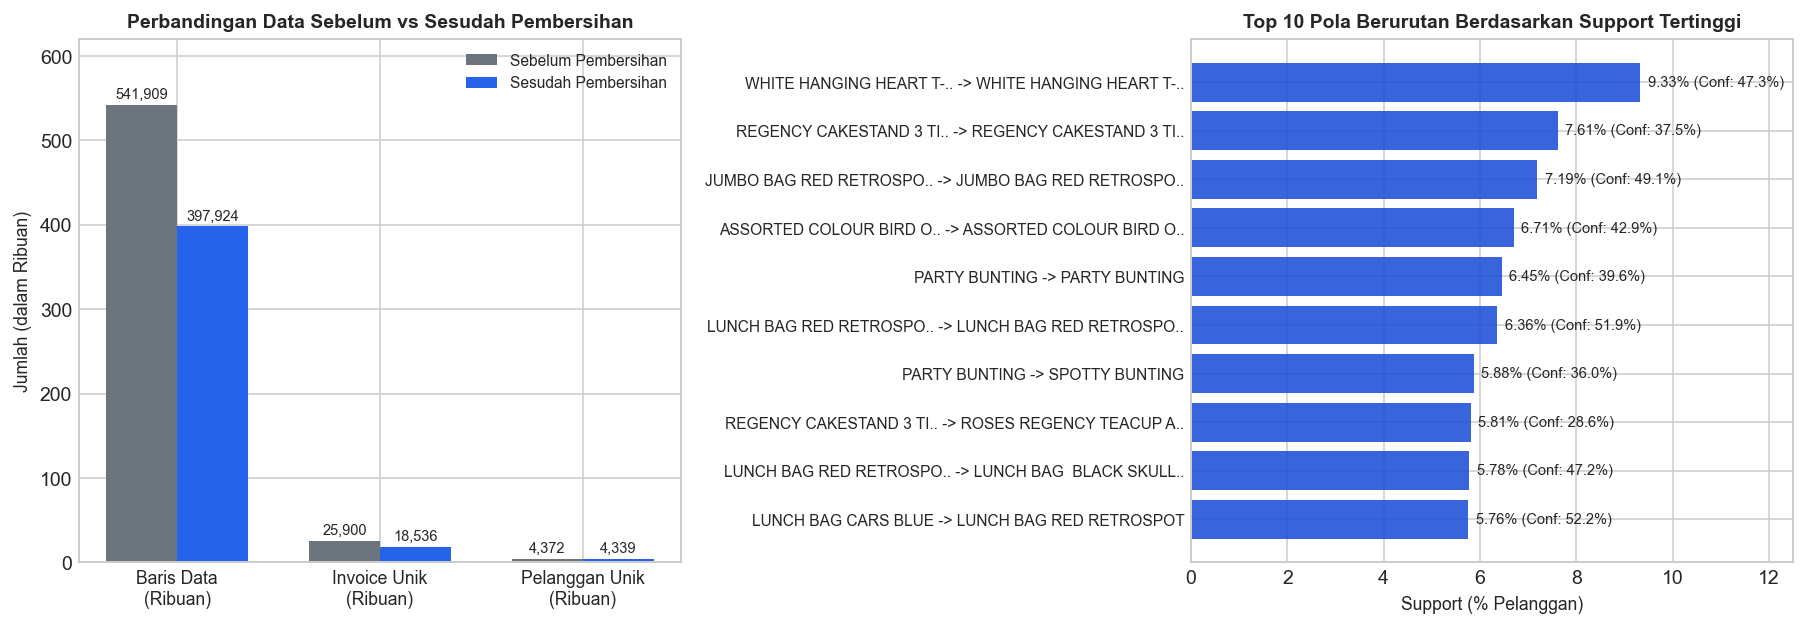

In [5]:
print("=== Top 10 Pola Berurutan Berdasarkan Support ===")
display(df_patterns[['Pattern', 'Length', 'Support Count', 'Support', 'Confidence']].head(10))

print("\n=== 3 Pola Berurutan Terbaik Berdasarkan Support Tertinggi ===")
top3_patterns = df_patterns[['Pattern', 'Length', 'Support Count', 'Support', 'Confidence']].head(3)
display(top3_patterns)

# Visualisasi hasil pembersihan & Top 10 pola berurutan
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
metrics_lbl = ['Baris Data\n(Ribuan)', 'Invoice Unik\n(Ribuan)', 'Pelanggan Unik\n(Ribuan)']
x = np.arange(3)
axes[0].bar(x - 0.17, [rows_before/1000, invoices_before/1000, customers_before/1000], 0.34, label='Sebelum Pembersihan', color='#6c757d')
axes[0].bar(x + 0.17, [rows_after/1000, invoices_after/1000, customers_after/1000], 0.34, label='Sesudah Pembersihan', color='#2563eb')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_lbl)
axes[0].set_title('Perbandingan Data Sebelum vs Sesudah Pembersihan')
axes[0].legend()

top10 = df_patterns.head(10).iloc[::-1]
axes[1].barh(top10['Pattern'], top10['Support'] * 100, color='#1d4ed8')
axes[1].set_xlabel('Support (% Pelanggan)')
axes[1].set_title('Top 10 Pola Berurutan Berdasarkan Support Tertinggi')
plt.tight_layout()
plt.show()

### 4. Laporan Singkat & Interpretasi Bisnis

1. **Hasil Eksplorasi & Pembersihan Data:**
   - Penghapusan baris tanpa `Description` (1.454 baris), tanpa `CustomerID` (135.080 baris), transaksi batal `'C'` (9.288 baris), dan `Quantity <= 0` (10.624 baris) menyaring data dari **541.909 baris (25.900 invoice, 4.372 pelanggan)** menjadi **397.924 baris bersih (18.536 invoice, 4.339 pelanggan)**.

2. **Penyesuaian Parameter Minimum Support:**
   - Pada titik awal `min_support = 0.01` (43 pelanggan), dihasilkan **27.225 pola berurutan** karena tingginya frekuensi pembelian berulang pelanggan grosir. Penyesuaian ke `min_support = 0.03` (130 pelanggan) atau `0.05` (216 pelanggan) menyaring hasil menjadi **605 pola** dan **52 pola** utama yang paling berdampak bisnis.

3. **Interpretasi 3 Pola Berurutan Terbaik (Berdasarkan Support Tertinggi):**
   - **Pola 1: `WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HANGING HEART T-LIGHT HOLDER`** (`Support = 0.0933` / 9,33%, `Confidence = 0.4731` / 47,31%)
     *Interpretasi:* Sebanyak 405 pelanggan (47,31% dari pembeli awal item ini) memesan kembali produk dekorasi tempat lilin ini pada transaksi berikutnya. Toko perlu menjaga *safety stock* dan mengaktifkan pengingat *restock* otomatis.
   - **Pola 2: `REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND 3 TIER`** (`Support = 0.0761` / 7,61%, `Confidence = 0.3746` / 37,46%)
     *Interpretasi:* Sebanyak 330 pelanggan melakukan pembelian berulang tempat kue 3 tingkat *Regency* (serta diikuti pembelian lintas-produk `REGENCY CAKESTAND 3 TIER -> ROSES REGENCY TEACUP AND SAUCER` dengan `Support = 5,81%`). Cocok diterapkan voucer diskon transaksi berikutnya pada seri *Regency*.
   - **Pola 3: `JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETROSPOT`** (`Support = 0.0719` / 7,19%, `Confidence = 0.4913` / 49,13%)
     *Interpretasi:* Hampir separuh (49,13%) pelanggan yang membeli *Jumbo Bag Red Retrospot* kembali memesan produk yang sama di invoice berikutnya. Strategi *volume discount* / paket langganan grosir sangat efektif untuk mempertahankan loyalitas pelanggan.

4. **Kesimpulan:**
   - Pola pembelian berurutan pada dataset *Online Retail* didominasi oleh **pembelian ulang (*repeat order*) produk-produk unggulan** serta **pembelian berurutan seri/motif pelengkap** (*Regency Series*, *Bunting*, dan *Lunch Bag*), selaras dengan karakteristik pelanggan yang mayoritas merupakan pedagang grosir (*wholesalers*).